# 363. Which k gives the same bits in every alphabet?

**Question.** A k-mer of 7 full amino acids and a k-mer of 30 hydrophobic/polar letters look very
different, but each letter says a different amount about the residue underneath. For a chosen
number of bits, which k does each of kmerseek's 24 alphabets need?

**Decision this informs.** Which k to run for each alphabet when a comparison should give every
alphabet the same information per k-mer, and whether one lookup can be reused for any proteome.

**Decision rule, written before the results.** Notebook 300 measured bits per letter on a gut
protein database (UHGP-90). If the k for 29.2 bits differs by at most 1 between that database and
this notebook's human and mouse proteins, for all 20 alphabets the two share, the lookup is reused
for any proteome. If not, each database gets its own lookup.

**What "bits" means here.** Bits per letter is the Shannon entropy of the alphabet's letters: how
much one letter narrows down which residue is there, from how often each letter occurs. Common
letters tell you less. Bits per k-mer is k x bits per letter, which assumes that neighbouring
positions are independent. Real proteins break that assumption, so these are upper limits.

**This is not an alignment bit score.** The bit score in kmerseek's hit tables comes from a scored
alignment and its fitted Karlin-Altschul parameters. These figures describe one k-mer, before
any search.

**Data.** No search was run. Inputs are the residue classes of kmerseek 0.5.0 (seanome/kmerseek
main 0643254, `src/rust/alphabets.rs`) and the amino acid frequencies in
`ortholog_analysis_utils.AA_FREQUENCIES`, counted on 145,111,545 residues of GENCODE v49 human and
vM38 mouse protein translations.

In [1]:
import sys
from pathlib import Path

import matplotlib as mpl
import numpy as np
import polars as pl
import seaborn as sns
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle

sys.path.insert(0, str(Path.cwd()))
import figure_utils as fu
import ortholog_analysis_utils as ou
import pubfig as pf

pf.use_style()

DATA = Path("363_data")
FIGURES = Path("figures/363")
DATA.mkdir(exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

TOOLS = (
    "No search run. Calculated from kmerseek 0.5.0 residue classes and human + mouse "
    "amino acid frequencies (GENCODE v49 + vM38)"
)
ALPHABETS = list(ou.KMERSEEK_ALPHABET_CLUSTERS)
PROTEIN_K = 7
BITS_PER_LETTER = {a: ou.entropy_per_symbol(a) for a in ALPHABETS}
REFERENCE_BITS = PROTEIN_K * BITS_PER_LETTER["protein20"]
MAX_BITS = 64
ROW_POSITIONS = fu.alphabet_positions(ALPHABETS)
GROUP_COLOURS = list(pf.OKABE_ITO.values())[: len(fu.ALPHABET_SIZE_GROUPS)]
print(
    f"{len(ALPHABETS)} alphabets; protein20 at k = {PROTEIN_K}: {REFERENCE_BITS:.1f} bits"
)

24 alphabets; protein20 at k = 7: 29.2 bits


## 1. Read k off a ruler

Each row is one alphabet, drawn as a ruler. The position along the bottom axis is bits per
k-mer, and each numbered tick is a k. To look up a value, pick the bits on the axis, go straight
up or down, and read the k on each ruler.

Rulers are spaced by bits per letter, so an alphabet with fewer bits per letter has its k values
packed closer. The alphabet with the fewest bits per letter, `cys2`, needs the largest k.

shape: (24, 5)
┌──────────────────────────┬───────────┬─────────────────┬────────────────────────────────┬─────────────────────────┐
│ alphabet                 ┆ n_letters ┆ bits_per_letter ┆ bits_if_letters_equally_common ┆ k_for_protein20_k7_bits │
│ ---                      ┆ ---       ┆ ---             ┆ ---                            ┆ ---                     │
│ str                      ┆ i64       ┆ f64             ┆ f64                            ┆ i64                     │
╞══════════════════════════╪═══════════╪═════════════════╪════════════════════════════════╪═════════════════════════╡
│ cys2                     ┆ 2         ┆ 0.150           ┆ 1.000                          ┆ 195                     │
│ hp_kyte_doolittle2       ┆ 2         ┆ 0.937           ┆ 1.000                          ┆ 31                      │
│ hp_lehninger2            ┆ 2         ┆ 1.000           ┆ 1.000                          ┆ 29                      │
│ hp_lehninger_c_nonpolar2 ┆ 2         ┆ 

figures/363/alphabet_ksize_ruler_by_bits_human_mouse.png


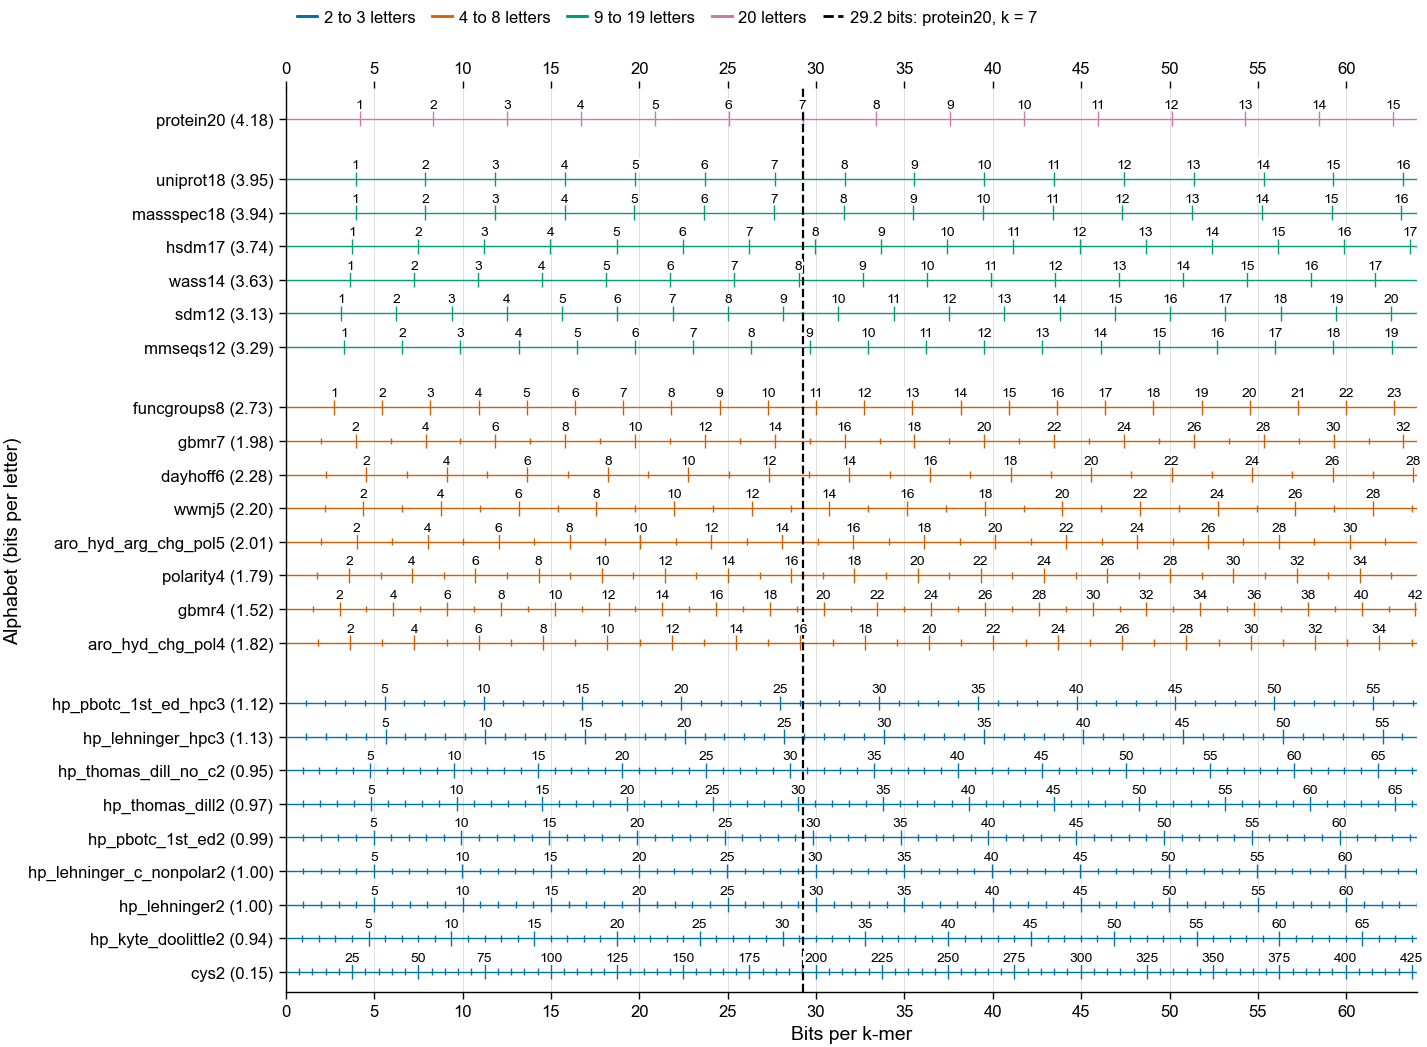

In [2]:
letters = pl.DataFrame(
    {
        "alphabet": ALPHABETS,
        "n_letters": [len(ou.KMERSEEK_ALPHABET_CLUSTERS[a]) for a in ALPHABETS],
        "bits_per_letter": [BITS_PER_LETTER[a] for a in ALPHABETS],
    }
).with_columns(
    pl.col("n_letters").log(2).alias("bits_if_letters_equally_common"),
    pl.struct("alphabet")
    .map_elements(
        lambda r: ou.ksize_for_bits(r["alphabet"], REFERENCE_BITS),
        return_dtype=pl.Int64,
    )
    .alias("k_for_protein20_k7_bits"),
)
letters.write_csv(DATA / "alphabet_bits_per_letter_human_mouse.tsv", separator="\t")
with pl.Config(tbl_rows=-1, tbl_width_chars=120, float_precision=3):
    print(letters)

LABEL_STEPS = (1, 2, 5, 10, 25, 50, 100)
MIN_LABEL_BITS = 2.3  # bits between labelled ticks, so two-digit labels do not touch
MIN_TICK_BITS = 0.4  # bits between small ticks, so they stay separate in print
K_LABEL_PT = 5


def first_step(steps, per_letter, smallest_gap):
    # The smallest step whose ticks sit at least smallest_gap bits apart.
    return next(s for s in steps if s * per_letter >= smallest_gap)


fig, ax = pf.figure(pf.TWO_COLUMN_MM, 135)
for alphabet in ALPHABETS:
    y = ROW_POSITIONS[alphabet]
    per_letter = BITS_PER_LETTER[alphabet]
    colour = GROUP_COLOURS[fu.alphabet_size_group(alphabet)]
    ax.hlines(y, 0, MAX_BITS, color=colour, linewidth=0.5, zorder=2)
    label_step = first_step(LABEL_STEPS, per_letter, MIN_LABEL_BITS)
    tick_step = first_step(LABEL_STEPS, per_letter, MIN_TICK_BITS)
    for k in range(tick_step, int(MAX_BITS / per_letter) + 1, tick_step):
        labelled = k % label_step == 0
        half_height = 0.22 if labelled else 0.1
        x = k * per_letter
        ax.vlines(
            x, y - half_height, y + half_height, color=colour, linewidth=0.5, zorder=2
        )
        if labelled:
            ax.text(
                x,
                y + 0.24,
                str(k),
                ha="center",
                va="bottom",
                fontsize=K_LABEL_PT,
                zorder=4,
                bbox=dict(facecolor="white", edgecolor="none", pad=0.3),
            )

ax.axvline(REFERENCE_BITS, color="black", linestyle="--", linewidth=0.8, zorder=3)
ax.set_yticks(
    list(ROW_POSITIONS.values()),
    [f"{a} ({BITS_PER_LETTER[a]:.2f})" for a in ROW_POSITIONS],
)
ax.set_ylim(-0.6, max(ROW_POSITIONS.values()) + 0.9)
ax.set_xlim(0, MAX_BITS)
ax.set_xticks(range(0, MAX_BITS + 1, 5))
ax.xaxis.grid(True, color="#d9d9d9", linewidth=0.3, zorder=0)
ax.tick_params(axis="x", top=True, labeltop=True)
ax.set_xlabel("Bits per k-mer")
ax.set_ylabel("Alphabet (bits per letter)")
handles = [
    Line2D(
        [], [], color=c, label=f"{lo} to {hi} letters" if lo != hi else f"{lo} letters"
    )
    for c, (lo, hi) in zip(GROUP_COLOURS, fu.ALPHABET_SIZE_GROUPS)
]
handles.append(
    Line2D(
        [],
        [],
        color="black",
        linestyle="--",
        label=f"{REFERENCE_BITS:.1f} bits: protein20, k = 7",
    )
)
fig.set_layout_engine(None)
fig.subplots_adjust(left=0.2, right=0.985, top=0.92, bottom=0.07)
fig.legend(
    handles=handles,
    loc="upper left",
    bbox_to_anchor=(0.2, 1.005),
    ncol=5,
    frameon=False,
)
pf.save(fig, FIGURES / "alphabet_ksize_ruler_by_bits_human_mouse")
print(FIGURES / "alphabet_ksize_ruler_by_bits_human_mouse.png")

## 2. The same lookup as a table

Each cell holds the k closest to the bits in that column. Only whole numbers of letters exist, so
k rarely lands exactly on the target. The colour shows the miss: white is an exact match, red
carries more bits than the column says and blue carries fewer. A miss can be as large as half of
one letter's bits, so alphabets with more bits per letter miss by more.

shape: (24, 12)
┌──────────────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┐
│ alphabet         ┆ 10 bits ┆ 15 bits ┆ 20 bits ┆ 25 bits ┆ 30 bits ┆ 35 bits ┆ 40 bits ┆ 45 bits ┆ 50 bits ┆ 55 bits ┆ 60 bits │
│ ---              ┆ ---     ┆ ---     ┆ ---     ┆ ---     ┆ ---     ┆ ---     ┆ ---     ┆ ---     ┆ ---     ┆ ---     ┆ ---     │
│ str              ┆ i64     ┆ i64     ┆ i64     ┆ i64     ┆ i64     ┆ i64     ┆ i64     ┆ i64     ┆ i64     ┆ i64     ┆ i64     │
╞══════════════════╪═════════╪═════════╪═════════╪═════════╪═════════╪═════════╪═════════╪═════════╪═════════╪═════════╪═════════╡
│ cys2             ┆ 67      ┆ 100     ┆ 133     ┆ 167     ┆ 200     ┆ 233     ┆ 267     ┆ 300     ┆ 334     ┆ 367     ┆ 400     │
│ hp_kyte_doolittl ┆ 11      ┆ 16      ┆ 21      ┆ 27      ┆ 32      ┆ 37      ┆ 43      ┆ 48      ┆ 53      ┆ 59      ┆ 64      │
│ e2               ┆         ┆         ┆         ┆         ┆       

figures/363/alphabet_ksize_lookup_table_by_bits_human_mouse.png


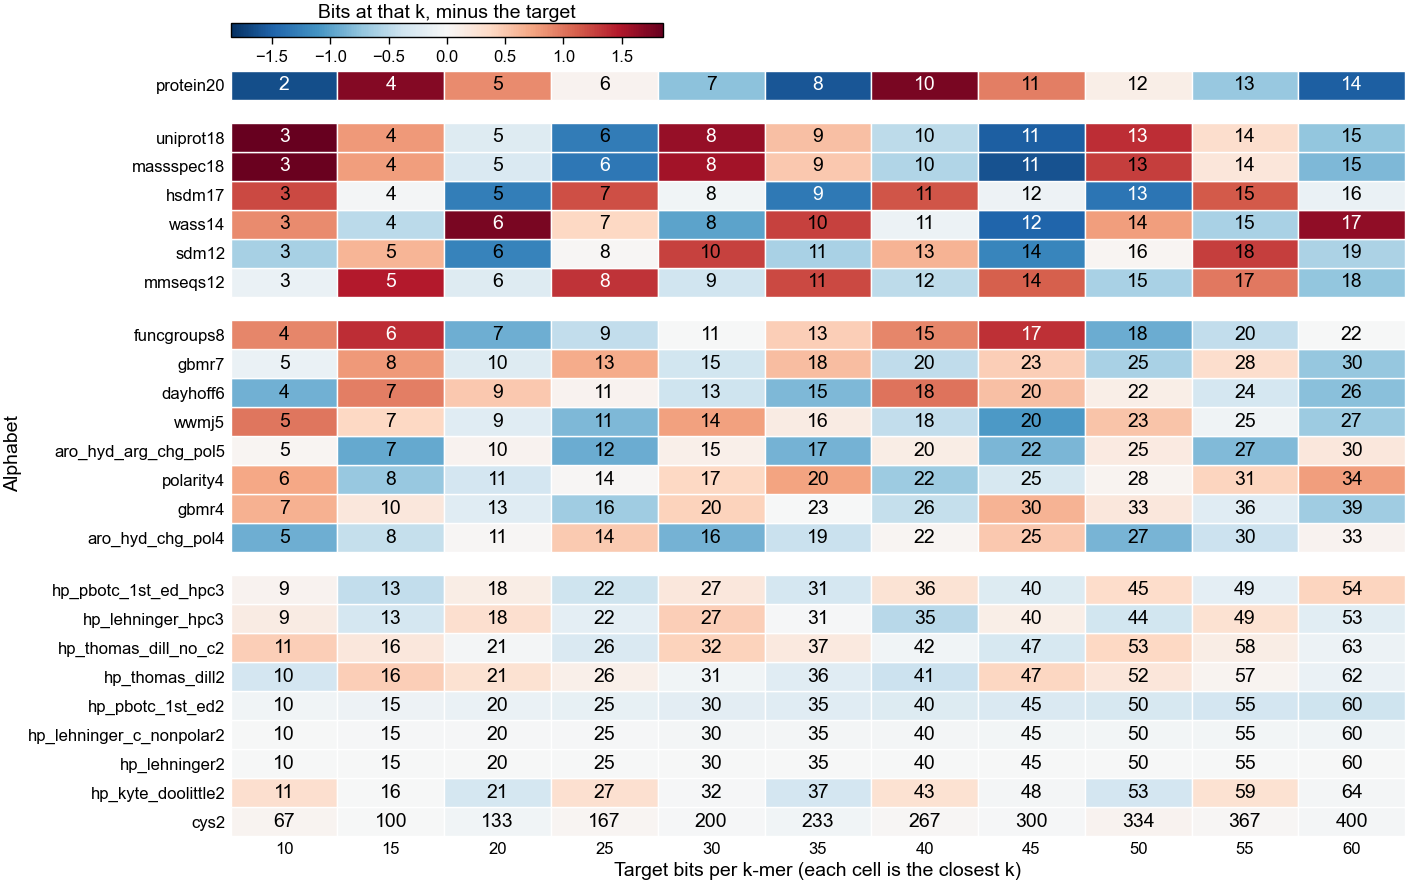

In [3]:
TARGET_BITS = list(range(10, 65, 5))
lookup = pl.DataFrame(
    [
        {
            "alphabet": a,
            "n_letters": len(ou.KMERSEEK_ALPHABET_CLUSTERS[a]),
            "target_bits": t,
            "ksize": ou.ksize_for_bits(a, t),
            "bits_at_ksize": ou.bits_per_kmer(a, ou.ksize_for_bits(a, t)),
        }
        for a in ROW_POSITIONS
        for t in TARGET_BITS
    ]
).with_columns(
    (pl.col("bits_at_ksize") - pl.col("target_bits")).alias("bits_over_target")
)
lookup.write_csv(DATA / "alphabet_ksize_lookup_by_bits_human_mouse.tsv", separator="\t")
wide = lookup.pivot(on="target_bits", index="alphabet", values="ksize")
wide = wide.rename({str(t): f"{t} bits" for t in TARGET_BITS})
with pl.Config(tbl_rows=-1, tbl_cols=-1, tbl_width_chars=130):
    print(wide)

largest_miss = lookup["bits_over_target"].abs().max()
print(lookup.sort(pl.col("bits_over_target").abs(), descending=True).head(3))
norm = mpl.colors.Normalize(-largest_miss, largest_miss)
cmap = mpl.colormaps["RdBu_r"]
fig, ax = pf.figure(pf.TWO_COLUMN_MM, 120)
for row in lookup.iter_rows(named=True):
    x = TARGET_BITS.index(row["target_bits"])
    y = ROW_POSITIONS[row["alphabet"]]
    ax.add_patch(
        Rectangle(
            (x - 0.5, y - 0.5),
            1,
            1,
            facecolor=cmap(norm(row["bits_over_target"])),
            edgecolor="white",
            linewidth=0.5,
        )
    )
    dark_cell = abs(row["bits_over_target"]) > 0.7 * largest_miss
    ax.text(
        x,
        y,
        str(row["ksize"]),
        ha="center",
        va="center",
        color="white" if dark_cell else "black",
    )
ax.set_xlim(-0.5, len(TARGET_BITS) - 0.5)
ax.set_ylim(-0.5, max(ROW_POSITIONS.values()) + 0.5)
ax.set_xticks(range(len(TARGET_BITS)), TARGET_BITS)
ax.set_yticks(list(ROW_POSITIONS.values()), list(ROW_POSITIONS))
ax.set_xlabel("Target bits per k-mer (each cell is the closest k)")
ax.set_ylabel("Alphabet")
ax.spines[["left", "bottom"]].set_visible(False)
ax.tick_params(length=0)
fig.set_layout_engine(None)
fig.subplots_adjust(left=0.17, right=0.985, top=0.89, bottom=0.08)
colour_key_ax = fig.add_axes([0.17, 0.925, 0.3, 0.015])
fig.colorbar(
    mpl.cm.ScalarMappable(norm=norm, cmap=cmap),
    cax=colour_key_ax,
    orientation="horizontal",
    label="Bits at that k, minus the target",
)
colour_key_ax.xaxis.set_label_position("top")
pf.save(fig, FIGURES / "alphabet_ksize_lookup_table_by_bits_human_mouse")
print(FIGURES / "alphabet_ksize_lookup_table_by_bits_human_mouse.png")

## 3. Does the lookup depend on which proteins set the letter frequencies?

This tests the decision rule from the top of the notebook. The human and mouse frequencies are
compared with the UHGP-90 values in
[notebook 300](300_mass_spec_peptide_source_lookup_uhgp90.ipynb), section 9, for the 20 alphabets
in both. Each k is the closest one to 29.2 bits, using that database's own bits per letter.

shape: (20, 6)
┌─────────────────────────┬─────────────────────────┬────────────────────────┬───────────────┬──────────┬──────────────┐
│ alphabet                ┆ bits_per_letter_human_m ┆ bits_per_letter_uhgp90 ┆ k_human_mouse ┆ k_uhgp90 ┆ k_difference │
│ ---                     ┆ ouse                    ┆ ---                    ┆ ---           ┆ ---      ┆ ---          │
│ str                     ┆ ---                     ┆ f64                    ┆ i64           ┆ i64      ┆ i64          │
│                         ┆ f64                     ┆                        ┆               ┆          ┆              │
╞═════════════════════════╪═════════════════════════╪════════════════════════╪═══════════════╪══════════╪══════════════╡
│ hp_kyte_doolittle2      ┆ 0.937                   ┆ 0.964                  ┆ 31            ┆ 30       ┆ -1           │
│ hp_thomas_dill_no_c2    ┆ 0.951                   ┆ 0.982                  ┆ 31            ┆ 30       ┆ -1           │
│ hp_thomas_dill2

figures/363/bits_per_letter_human_mouse_vs_uhgp90.png


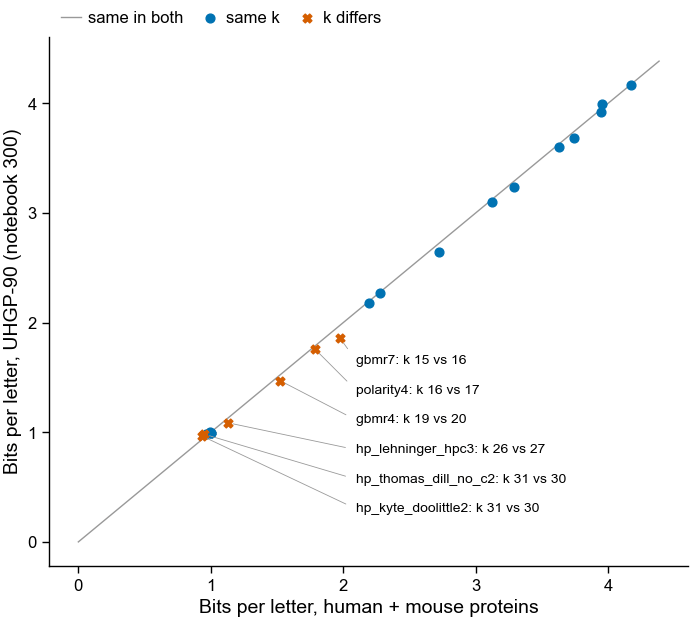

In [4]:
uhgp = pl.read_csv("300_data/settings_one_k_per_alphabet.tsv", separator="\t").select(
    "alphabet", pl.col("bits_per_position").alias("bits_per_letter_uhgp90")
)
both = (
    letters.select(
        "alphabet", pl.col("bits_per_letter").alias("bits_per_letter_human_mouse")
    )
    .join(uhgp, on="alphabet", how="inner")
    .with_columns(
        (pl.lit(REFERENCE_BITS) / pl.col("bits_per_letter_human_mouse"))
        .round()
        .cast(int)
        .alias("k_human_mouse"),
        (pl.lit(REFERENCE_BITS) / pl.col("bits_per_letter_uhgp90"))
        .round()
        .cast(int)
        .alias("k_uhgp90"),
    )
    .with_columns((pl.col("k_uhgp90") - pl.col("k_human_mouse")).alias("k_difference"))
    .sort("k_human_mouse", descending=True)
)
both.write_csv(DATA / "bits_per_letter_human_mouse_vs_uhgp90.tsv", separator="\t")
with pl.Config(tbl_rows=-1, tbl_width_chars=120, float_precision=3):
    print(both)
n_within_one = both.filter(pl.col("k_difference").abs() <= 1).height
print(f"{n_within_one} of {both.height} alphabets: k differs by at most 1")
print(f"{both.filter(pl.col('k_difference') == 0).height} of {both.height}: same k")

fig, ax = pf.figure(pf.ONE_COLUMN_MM, 80)
axis_limit = both["bits_per_letter_human_mouse"].max() * 1.05
ax.plot(
    [0, axis_limit], [0, axis_limit], color=pf.GREY, linewidth=0.5, label="same in both"
)
for k_difference, marker, colour in (
    (False, "o", pf.OKABE_ITO["blue"]),
    (True, "X", pf.OKABE_ITO["vermillion"]),
):
    subset = both.filter((pl.col("k_difference") != 0) == k_difference)
    ax.scatter(
        subset["bits_per_letter_human_mouse"],
        subset["bits_per_letter_uhgp90"],
        s=10,
        marker=marker,
        color=colour,
        zorder=3,
        label="k differs" if k_difference else "same k",
    )
    if k_difference:
        for i, row in enumerate(
            subset.sort("bits_per_letter_human_mouse", descending=True).iter_rows(
                named=True
            )
        ):
            ax.annotate(
                f"{row['alphabet']}: k {row['k_human_mouse']} vs {row['k_uhgp90']}",
                (row["bits_per_letter_human_mouse"], row["bits_per_letter_uhgp90"]),
                xytext=(2.1, 1.65 - 0.27 * i),
                textcoords="data",
                fontsize=K_LABEL_PT,
                va="center",
                arrowprops=dict(
                    arrowstyle="-",
                    color=pf.GREY,
                    linewidth=0.3,
                    shrinkB=2,
                    relpos=(0, 0.5),
                ),
            )
ax.set_xlabel("Bits per letter, human + mouse proteins")
ax.set_ylabel("Bits per letter, UHGP-90 (notebook 300)")
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=3, frameon=False)
pf.save(fig, FIGURES / "bits_per_letter_human_mouse_vs_uhgp90")
print(FIGURES / "bits_per_letter_human_mouse_vs_uhgp90.png")

## 4. Bits against k, one line per alphabet

Each line is one alphabet, and its slope is that alphabet's bits per letter. A steep line reaches
a given number of bits at a small k. To compare alphabets, go across at one height and read k off
the bottom axis at each line. The legend lists alphabets from steepest to shallowest.

Colours alone cannot separate 24 lines, so each line also has its own marker, drawn every 5 k.
The 2-letter hydrophobic/polar lines nearly overlap because their bits per letter run only from
0.94 to 1.00.

shape: (24, 2)
┌──────────────────────────┬─────────────────┐
│ alphabet                 ┆ bits_per_letter │
│ ---                      ┆ ---             │
│ str                      ┆ f64             │
╞══════════════════════════╪═════════════════╡
│ protein20                ┆ 4.177           │
│ uniprot18                ┆ 3.951           │
│ massspec18               ┆ 3.944           │
│ hsdm17                   ┆ 3.742           │
│ wass14                   ┆ 3.626           │
│ mmseqs12                 ┆ 3.293           │
│ sdm12                    ┆ 3.127           │
│ funcgroups8              ┆ 2.727           │
│ dayhoff6                 ┆ 2.278           │
│ wwmj5                    ┆ 2.197           │
│ aro_hyd_arg_chg_pol5     ┆ 2.007           │
│ gbmr7                    ┆ 1.976           │
│ aro_hyd_chg_pol4         ┆ 1.820           │
│ polarity4                ┆ 1.787           │
│ gbmr4                    ┆ 1.522           │
│ hp_lehninger_hpc3        ┆ 1.128           

figures/363/bits_vs_ksize_by_alphabet_human_mouse.png


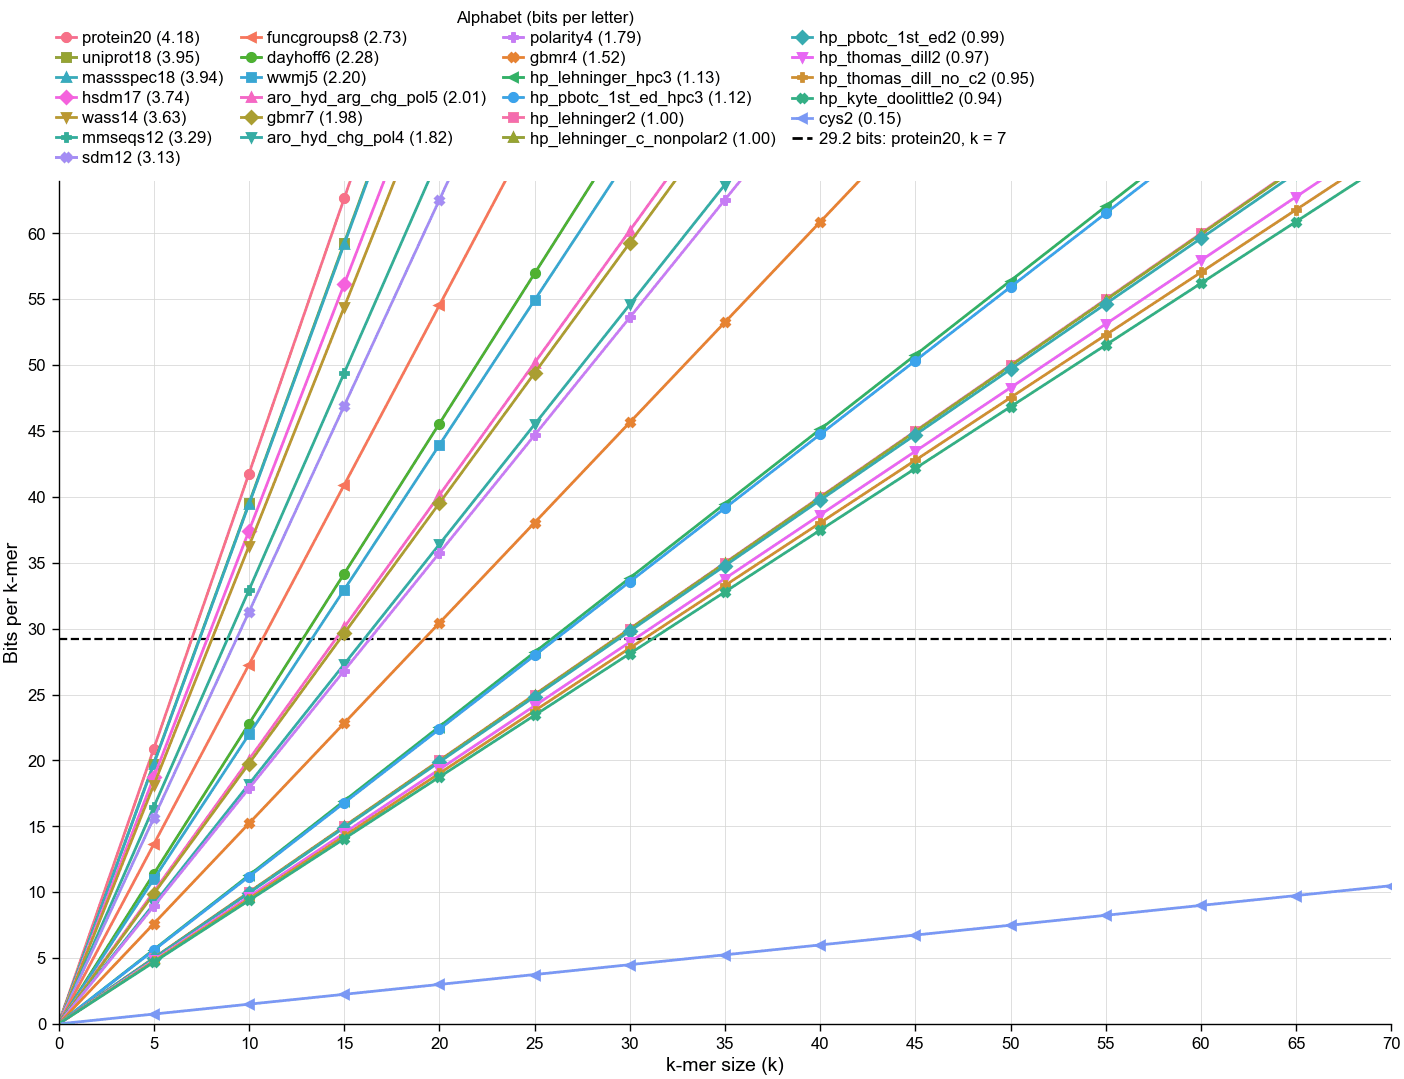

In [5]:
MAX_K = 70
MARKER_EVERY_K = 5
MARKERS = ("o", "s", "^", "D", "v", "P", "X", "<")
HUE_STEP = 7  # 7 shares no factor with 24, so every alphabet gets its own hue
steepest_first = sorted(ALPHABETS, key=BITS_PER_LETTER.get, reverse=True)
hues = sns.color_palette("husl", len(steepest_first))
alphabet_colours = {
    a: hues[i * HUE_STEP % len(hues)] for i, a in enumerate(steepest_first)
}

with pl.Config(tbl_rows=-1, tbl_width_chars=120, float_precision=3):
    print(
        letters.select("alphabet", "bits_per_letter").sort(
            "bits_per_letter", descending=True
        )
    )

fig, ax = pf.figure(pf.TWO_COLUMN_MM, 140)
ks = np.arange(0, MAX_K + 1)
for i, alphabet in enumerate(steepest_first):
    ax.plot(
        ks,
        ks * BITS_PER_LETTER[alphabet],
        color=alphabet_colours[alphabet],
        marker=MARKERS[i % len(MARKERS)],
        markevery=(MARKER_EVERY_K, MARKER_EVERY_K),
        label=f"{alphabet} ({BITS_PER_LETTER[alphabet]:.2f})",
    )
ax.axhline(REFERENCE_BITS, color="black", linestyle="--", linewidth=0.8, zorder=1)
ax.set_xlim(0, MAX_K)
ax.set_ylim(0, MAX_BITS)
ax.set_xticks(range(0, MAX_K + 1, 5))
ax.set_yticks(range(0, MAX_BITS + 1, 5))
ax.grid(True, color="#d9d9d9", linewidth=0.3, zorder=0)
ax.set_xlabel("k-mer size (k)")
ax.set_ylabel("Bits per k-mer")
handles, labels = ax.get_legend_handles_labels()
handles.append(Line2D([], [], color="black", linestyle="--"))
labels.append(f"{REFERENCE_BITS:.1f} bits: protein20, k = 7")
fig.set_layout_engine(None)
fig.subplots_adjust(left=0.06, right=0.985, top=0.835, bottom=0.07)
fig.legend(
    handles,
    labels,
    title="Alphabet (bits per letter)",
    loc="upper left",
    bbox_to_anchor=(0.05, 1.0),
    ncol=4,
    frameon=False,
)
pf.save(fig, FIGURES / "bits_vs_ksize_by_alphabet_human_mouse")
print(FIGURES / "bits_vs_ksize_by_alphabet_human_mouse.png")

# Summary and Conclusions

## Background

kmerseek's alphabets carry different amounts of information per letter, so the same k means
different things in each. This notebook gives the k for any number of bits per k-mer, across all
24 alphabets in kmerseek 0.5.0.

## Summary and Conclusions

* kmerseek's 24 alphabets carry 0.15 to 4.18 bits per letter, so matching protein20 at k = 7
  (29.2 bits) takes k = 7 to k = 195.
* `hp_lehninger2` at k = 29 carries 29.0 bits against protein20's 29.2 at k = 7, because each
  hydrophobic/polar letter carries 1.00 bit.
* Assuming equally common letters overstates `gbmr7` by 42%: 2.81 bits per letter against a
  measured 1.98.
* Rounding to a whole k misses the table's targets by at most 1.85 bits (`uniprot18` at 10 bits)
  and by at most 0.46 bits for 2-letter alphabets.
* The k for 29.2 bits matches between human + mouse and UHGP-90 for 14 of 20 alphabets and is
  off by 1 for the other 6, so one lookup can be reused.

**Decision.** The rule at the top passes: 20 of 20 alphabets are within 1 of each other. Use this
lookup for any proteome, and expect up to 1 k of difference on a database with an unusual
composition.

## Analysis Details

Bits per letter is the Shannon entropy of each alphabet's letters. Each letter's frequency is the
sum of the human and mouse frequencies of its residues. The closest k is bits / bits per letter,
rounded, with a minimum of 1. Section 3 repeats the k calculation with the UHGP-90 values from
notebook 300.

## Supplementary Information

- Tables: `363_data/alphabet_bits_per_letter_human_mouse.tsv`,
  `363_data/alphabet_ksize_lookup_by_bits_human_mouse.tsv`,
  `363_data/bits_per_letter_human_mouse_vs_uhgp90.tsv`.
- Figures: `figures/363/alphabet_ksize_ruler_by_bits_human_mouse.png`,
  `figures/363/alphabet_ksize_lookup_table_by_bits_human_mouse.png`,
  `figures/363/bits_per_letter_human_mouse_vs_uhgp90.png`,
  `figures/363/bits_vs_ksize_by_alphabet_human_mouse.png`.
- Limits: positions are treated as independent, so real k-mers carry fewer bits than shown. The
  figures do not say whether a k can seed in a given protein. `cys2` is the clearest case: k = 195
  is longer than many proteins.
- Four alphabets are new since notebook 300's table and have no UHGP-90 value here: `cys2`,
  `hp_pbotc_1st_ed_hpc3`, `aro_hyd_chg_pol4` and `aro_hyd_arg_chg_pol5`.

## References

- kmerseek 0.5.0, seanome/kmerseek main 0643254, `src/rust/alphabets.rs`.
- [Notebook 300](300_mass_spec_peptide_source_lookup_uhgp90.ipynb), section 9.

In [6]:
summary_md = r"""
# Summary and Conclusions

## Background

kmerseek's alphabets carry different amounts of information per letter, so the same k means
different things in each. This notebook gives the k for any number of bits per k-mer, across all
24 alphabets in kmerseek 0.5.0.

## Summary and Conclusions

* kmerseek's 24 alphabets carry 0.15 to 4.18 bits per letter, so matching protein20 at k = 7
  (29.2 bits) takes k = 7 to k = 195.
* `hp_lehninger2` at k = 29 carries 29.0 bits against protein20's 29.2 at k = 7, because each
  hydrophobic/polar letter carries 1.00 bit.
* Assuming equally common letters overstates `gbmr7` by 42%: 2.81 bits per letter against a
  measured 1.98.
* Rounding to a whole k misses the table's targets by at most 1.85 bits (`uniprot18` at 10 bits)
  and by at most 0.46 bits for 2-letter alphabets.
* The k for 29.2 bits matches between human + mouse and UHGP-90 for 14 of 20 alphabets and is
  off by 1 for the other 6, so one lookup can be reused.

**Decision.** The rule at the top passes: 20 of 20 alphabets are within 1 of each other. Use this
lookup for any proteome, and expect up to 1 k of difference on a database with an unusual
composition.

## Analysis Details

Bits per letter is the Shannon entropy of each alphabet's letters. Each letter's frequency is the
sum of the human and mouse frequencies of its residues. The closest k is bits / bits per letter,
rounded, with a minimum of 1. Section 3 repeats the k calculation with the UHGP-90 values from
notebook 300.

## Supplementary Information

- Tables: `363_data/alphabet_bits_per_letter_human_mouse.tsv`,
  `363_data/alphabet_ksize_lookup_by_bits_human_mouse.tsv`,
  `363_data/bits_per_letter_human_mouse_vs_uhgp90.tsv`.
- Figures: `figures/363/alphabet_ksize_ruler_by_bits_human_mouse.png`,
  `figures/363/alphabet_ksize_lookup_table_by_bits_human_mouse.png`,
  `figures/363/bits_per_letter_human_mouse_vs_uhgp90.png`,
  `figures/363/bits_vs_ksize_by_alphabet_human_mouse.png`.
- Limits: positions are treated as independent, so real k-mers carry fewer bits than shown. The
  figures do not say whether a k can seed in a given protein. `cys2` is the clearest case: k = 195
  is longer than many proteins.
- Four alphabets are new since notebook 300's table and have no UHGP-90 value here: `cys2`,
  `hp_pbotc_1st_ed_hpc3`, `aro_hyd_chg_pol4` and `aro_hyd_arg_chg_pol5`.

## References

- kmerseek 0.5.0, seanome/kmerseek main 0643254, `src/rust/alphabets.rs`.
- [Notebook 300](300_mass_spec_peptide_source_lookup_uhgp90.ipynb), section 9.
"""
print(summary_md)


# Summary and Conclusions

## Background

kmerseek's alphabets carry different amounts of information per letter, so the same k means
different things in each. This notebook gives the k for any number of bits per k-mer, across all
24 alphabets in kmerseek 0.5.0.

## Summary and Conclusions

* kmerseek's 24 alphabets carry 0.15 to 4.18 bits per letter, so matching protein20 at k = 7
  (29.2 bits) takes k = 7 to k = 195.
* `hp_lehninger2` at k = 29 carries 29.0 bits against protein20's 29.2 at k = 7, because each
  hydrophobic/polar letter carries 1.00 bit.
* Assuming equally common letters overstates `gbmr7` by 42%: 2.81 bits per letter against a
  measured 1.98.
* Rounding to a whole k misses the table's targets by at most 1.85 bits (`uniprot18` at 10 bits)
  and by at most 0.46 bits for 2-letter alphabets.
* The k for 29.2 bits matches between human + mouse and UHGP-90 for 14 of 20 alphabets and is
  off by 1 for the other 6, so one lookup can be reused.

**Decision.** The rule at th